 <style>
.markdown-content {
    direction: rtl;
    text-align: right;
}

.markdown-content pre {
    direction: ltr;
    text-align: left;
}

.markdown-content code {
    direction: ltr;
    text-align: left;
}
</style>

<div class="markdown-content">

## فاز ۱ — شناخت داده و EDA

1. Problem Definition — تعریف مسئله، مشخص‌کردن هدف پیش‌بینی و نوع مسئله
2. Load Dataset — بارگذاری دیتاست `California Housing` با `Scikit-learn` و تبدیل آن به `DataFrame`
3. Data Inspection — بررسی ابعاد، ستون‌ها، نوع داده‌ها و چند ردیف اول
4. Data Quality — بررسی مقادیر گمشده، داده‌های تکراری و مقادیر غیرعادی
5. Descriptive Statistics — محاسبه میانگین، میانه، انحراف معیار، کمینه و بیشینه
6. Univariate Analysis — بررسی توزیع هر ویژگی با `Histogram` و `Box Plot`
7. Bivariate Analysis — بررسی رابطه ویژگی‌ها با متغیر هدف و رسم `Scatter Plot`
8. Correlation Analysis — بررسی هم‌بستگی ویژگی‌ها با یکدیگر و با متغیر هدف

In [ ]:
# 2. Load dataset
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing

housing = fetch_california_housing(as_frame=True)

df = housing.frame.copy()

print("Dataset loaded successfully!")
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

Dataset loaded successfully!
Shape: (20640, 9)

Columns:
['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'MedHouseVal']


In [86]:
# 3. Data Inspection

print(df.shape)
print(df.columns)
print(df.dtypes)
print(df.head())
print(df.tail())
print(df.info)

(20640, 9)
Index(['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup',
       'Latitude', 'Longitude', 'MedHouseVal'],
      dtype='str')
MedInc         float64
HouseAge       float64
AveRooms       float64
AveBedrms      float64
Population     float64
AveOccup       float64
Latitude       float64
Longitude      float64
MedHouseVal    float64
dtype: object
   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  MedHouseVal  
0    -122.23        4.526  
1    -122.22        3.585  
2    -122.24        3.521  
3    -122.25        3.413  
4    -122.25        3.42

In [87]:
# 4. Data Quality

print("Missing values per column:")
print(df.isnull().sum())

print("\nTotal missing values:")
print(df.isnull().sum().sum())

print("Number of duplicated rows:")
print(df.duplicated().sum())

print("Minimum values:")
print(df.min())

print("\nMaximum values:")
print(df.max())

print(df.describe().T)

Missing values per column:
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

Total missing values:
0
Number of duplicated rows:
0
Minimum values:
MedInc           0.499900
HouseAge         1.000000
AveRooms         0.846154
AveBedrms        0.333333
Population       3.000000
AveOccup         0.692308
Latitude        32.540000
Longitude     -124.350000
MedHouseVal      0.149990
dtype: float64

Maximum values:
MedInc            15.000100
HouseAge          52.000000
AveRooms         141.909091
AveBedrms         34.066667
Population     35682.000000
AveOccup        1243.333333
Latitude          41.950000
Longitude       -114.310000
MedHouseVal        5.000010
dtype: float64
               count         mean          std         min         25%  \
MedInc       20640.0     3.870671     1.899822    0.499900    2.563400   
HouseAge     20640.0    28.639486    12.585558    1.0000

In [88]:
# 5. Descriptive Statistics

numeric_cols = df.select_dtypes(include="number").columns

stats = pd.DataFrame({
    "Mean": df[numeric_cols].mean(),
    "Median": df[numeric_cols].median(),
    "Std": df[numeric_cols].std(),
    "Min": df[numeric_cols].min(),
    "Max": df[numeric_cols].max()
})

print(stats.round(2))
print(df.quantile([0.25, 0.50, 0.75]).T.round(2))

                Mean   Median      Std     Min       Max
MedInc          3.87     3.53     1.90    0.50     15.00
HouseAge       28.64    29.00    12.59    1.00     52.00
AveRooms        5.43     5.23     2.47    0.85    141.91
AveBedrms       1.10     1.05     0.47    0.33     34.07
Population   1425.48  1166.00  1132.46    3.00  35682.00
AveOccup        3.07     2.82    10.39    0.69   1243.33
Latitude       35.63    34.26     2.14   32.54     41.95
Longitude    -119.57  -118.49     2.00 -124.35   -114.31
MedHouseVal     2.07     1.80     1.15    0.15      5.00
               0.25     0.50     0.75
MedInc         2.56     3.53     4.74
HouseAge      18.00    29.00    37.00
AveRooms       4.44     5.23     6.05
AveBedrms      1.01     1.05     1.10
Population   787.00  1166.00  1725.00
AveOccup       2.43     2.82     3.28
Latitude      33.93    34.26    37.71
Longitude   -121.80  -118.49  -118.01
MedHouseVal    1.20     1.80     2.65


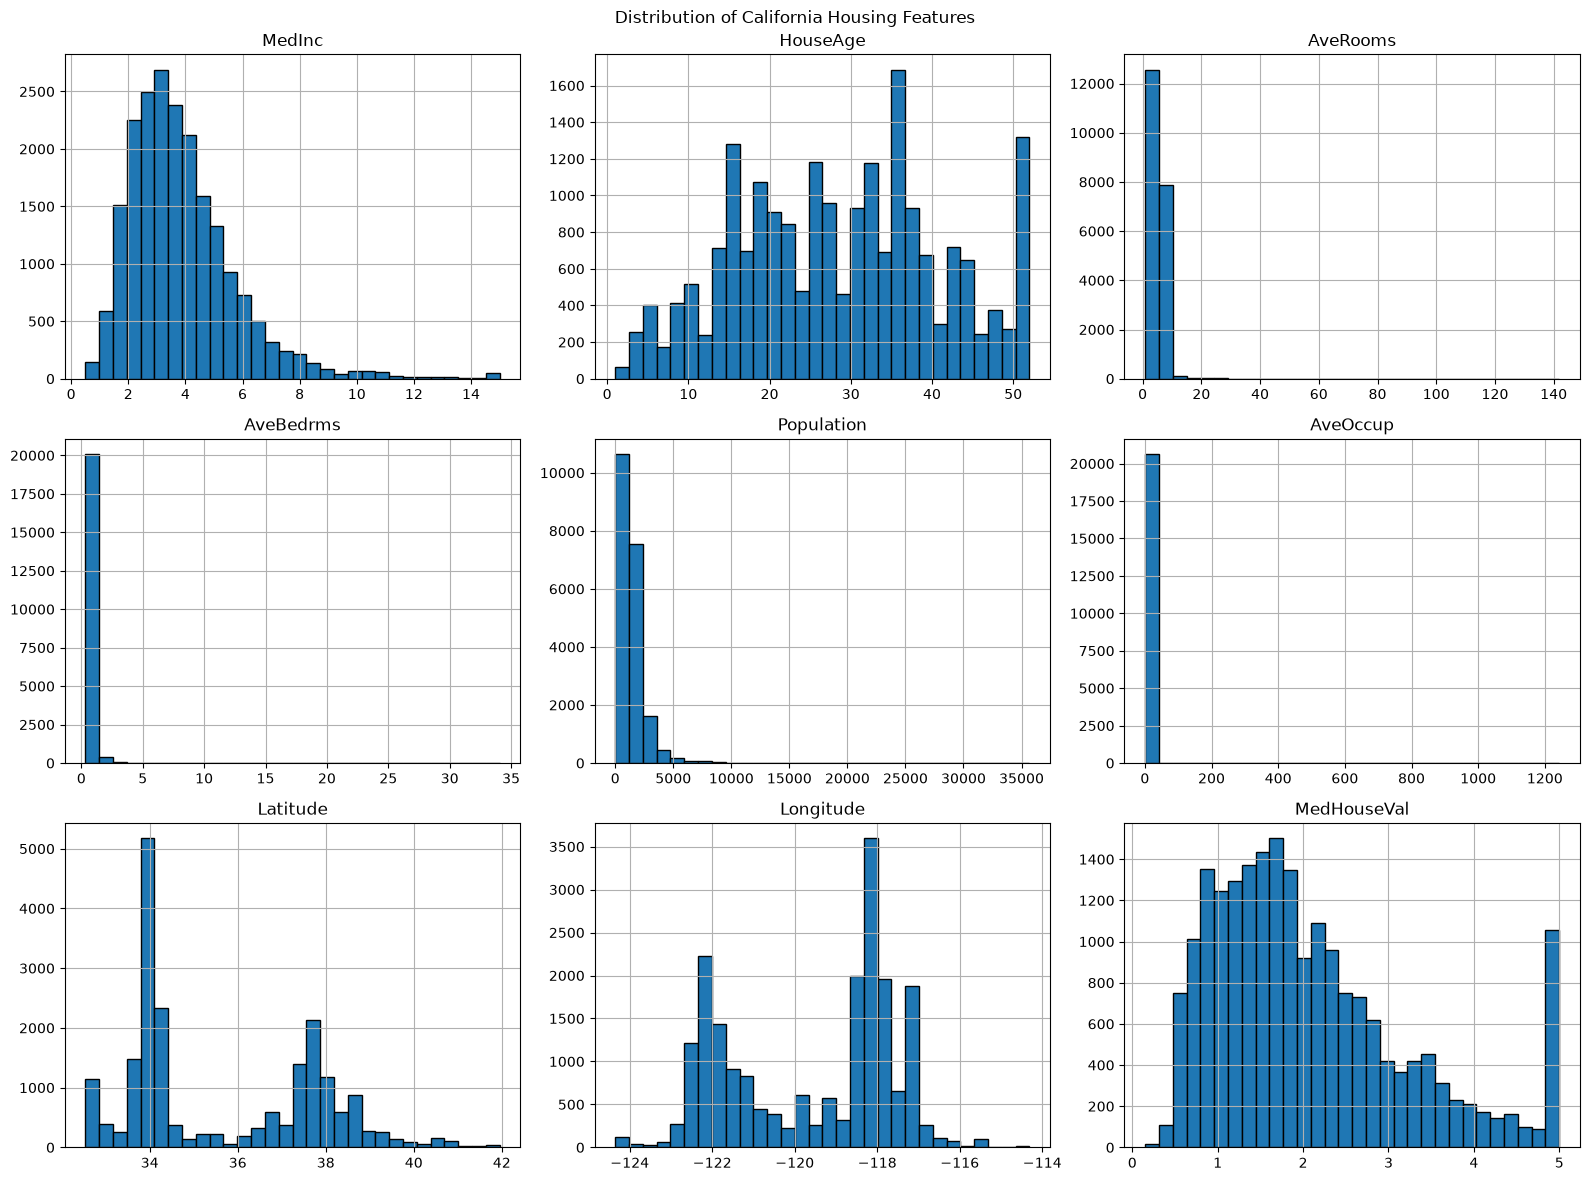

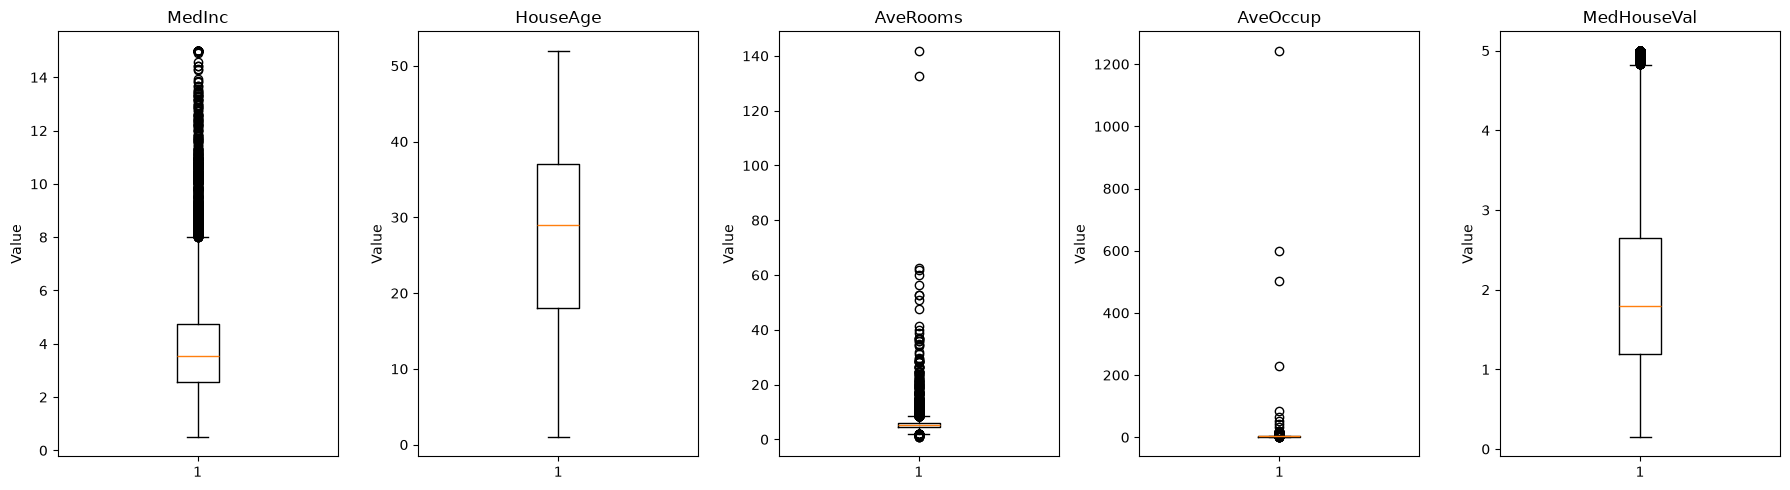

In [89]:
# 6. Univariate Analysis

df.hist(
    figsize=(16, 12),
    bins=30,
    edgecolor="black"
)

plt.suptitle("Distribution of California Housing Features")
plt.tight_layout()

columns = ["MedInc", "HouseAge", "AveRooms", "AveOccup", "MedHouseVal"]

fig, axes = plt.subplots(1, len(columns), figsize=(18, 5))

for ax, col in zip(axes, columns):
    ax.boxplot(df[col].dropna())
    ax.set_title(col)
    ax.set_ylabel("Value")

plt.tight_layout()
plt.show()

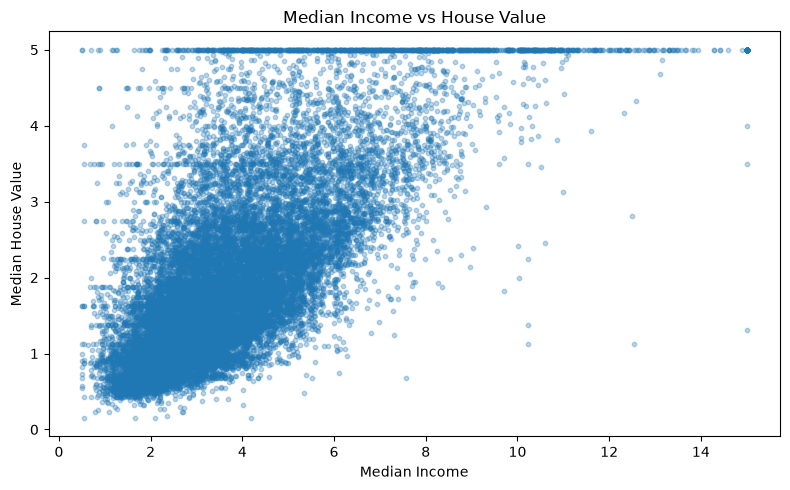

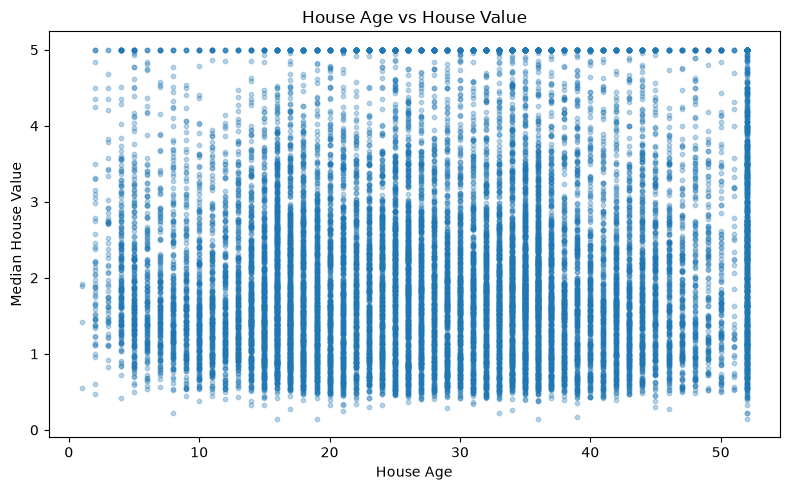

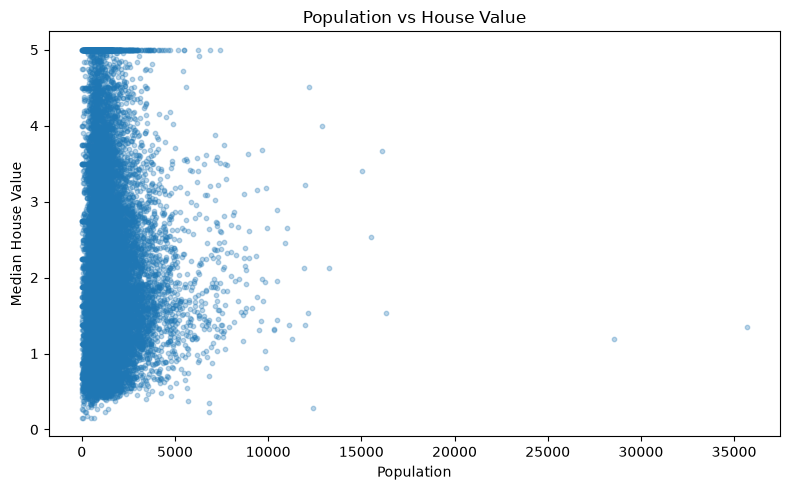

In [90]:
# 7. Bivariate Analysis

plt.figure(figsize=(8, 5))

plt.scatter(
    df["MedInc"],
    df["MedHouseVal"],
    alpha=0.3,
    s=10
)

plt.xlabel("Median Income")
plt.ylabel("Median House Value")
plt.title("Median Income vs House Value")

plt.tight_layout()

plt.figure(figsize=(8, 5))

plt.scatter(
    df["HouseAge"],
    df["MedHouseVal"],
    alpha=0.3,
    s=10
)

plt.xlabel("House Age")
plt.ylabel("Median House Value")
plt.title("House Age vs House Value")

plt.tight_layout()

plt.figure(figsize=(8, 5))

plt.scatter(
    df["Population"],
    df["MedHouseVal"],
    alpha=0.3,
    s=10
)

plt.xlabel("Population")
plt.ylabel("Median House Value")
plt.title("Population vs House Value")

plt.tight_layout()
plt.show()

             MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  \
MedInc         1.00     -0.12      0.33      -0.06        0.00      0.02   
HouseAge      -0.12      1.00     -0.15      -0.08       -0.30      0.01   
AveRooms       0.33     -0.15      1.00       0.85       -0.07     -0.00   
AveBedrms     -0.06     -0.08      0.85       1.00       -0.07     -0.01   
Population     0.00     -0.30     -0.07      -0.07        1.00      0.07   
AveOccup       0.02      0.01     -0.00      -0.01        0.07      1.00   
Latitude      -0.08      0.01      0.11       0.07       -0.11      0.00   
Longitude     -0.02     -0.11     -0.03       0.01        0.10      0.00   
MedHouseVal    0.69      0.11      0.15      -0.05       -0.02     -0.02   

             Latitude  Longitude  MedHouseVal  
MedInc          -0.08      -0.02         0.69  
HouseAge         0.01      -0.11         0.11  
AveRooms         0.11      -0.03         0.15  
AveBedrms        0.07       0.01        -0.05  

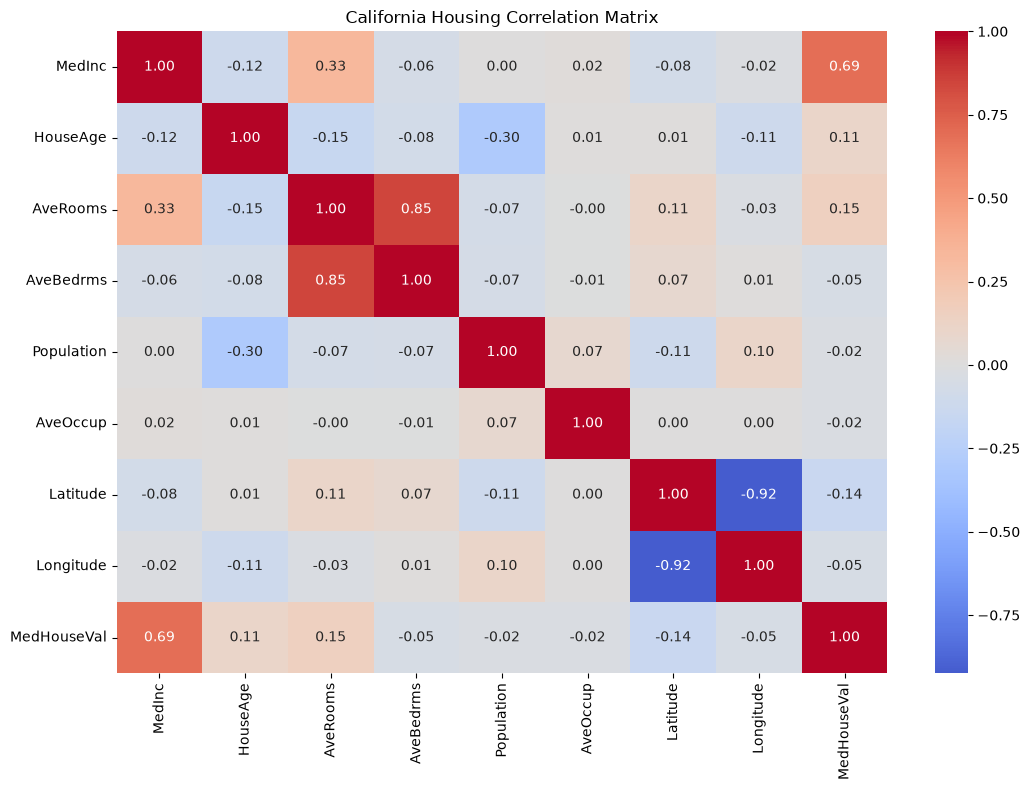

Correlation with MedHouseVal:
MedInc        0.688
AveRooms      0.152
HouseAge      0.106
AveOccup     -0.024
Population   -0.025
Longitude    -0.046
AveBedrms    -0.047
Latitude     -0.144
Name: MedHouseVal, dtype: float64


In [92]:
# 8. Correlation Analysis

corr = df.corr(numeric_only=True)

print(corr.round(2))

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(11, 8))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("California Housing Correlation Matrix")
plt.tight_layout()
plt.show()

target_corr = (
    corr["MedHouseVal"]
    .drop("MedHouseVal")
    .sort_values(ascending=False)
)

print("Correlation with MedHouseVal:")
print(target_corr.round(3))

<style>
.markdown-content {
    direction: rtl;
    text-align: right;
}

.markdown-content pre {
    direction: ltr;
    text-align: left;
}

.markdown-content code {
    direction: ltr;
    text-align: left;
}
</style>

<div class="markdown-content">

## فاز ۲ — آماده‌سازی داده

9. Define X and y — تفکیک ویژگی‌ها (`X`) و متغیر هدف (`y`)
10. Train-Test Split — تقسیم داده به مجموعه‌های `Train` و `Test`
11. Preprocessing — بررسی نیاز به `Imputation`، `Scaling` و سایر تبدیل‌ها
12. Build Pipeline — ساخت `Pipeline` برای ترکیب پیش‌پردازش و مدل

In [97]:
# 9. Define X and y

X = df.drop(columns=["MedHouseVal"])

# Target
y = df["MedHouseVal"]

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nFeatures:")
print(X.columns.tolist())

print("\nTarget preview:")
print(y.head())

X shape: (20640, 8)
y shape: (20640,)

Features:
['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']

Target preview:
0    4.526
1    3.585
2    3.521
3    3.413
4    3.422
Name: MedHouseVal, dtype: float64


In [98]:
# 10. Train-Test Split

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (16512, 8)
X_test: (4128, 8)
y_train: (16512,)
y_test: (4128,)


In [99]:
# 11. Preprocessing

print("Missing values in X_train:")
print(X_train.isnull().sum())

print("\nMissing values in X_test:")
print(X_test.isnull().sum())

print(X_train.describe().T[["mean", "std", "min", "max"]].round(2))

Missing values in X_train:
MedInc        0
HouseAge      0
AveRooms      0
AveBedrms     0
Population    0
AveOccup      0
Latitude      0
Longitude     0
dtype: int64

Missing values in X_test:
MedInc        0
HouseAge      0
AveRooms      0
AveBedrms     0
Population    0
AveOccup      0
Latitude      0
Longitude     0
dtype: int64
               mean      std     min       max
MedInc         3.88     1.90    0.50     15.00
HouseAge      28.61    12.60    1.00     52.00
AveRooms       5.44     2.39    0.89    141.91
AveBedrms      1.10     0.43    0.33     25.64
Population  1426.45  1137.06    3.00  35682.00
AveOccup       3.10    11.58    0.69   1243.33
Latitude      35.64     2.14   32.55     41.95
Longitude   -119.58     2.01 -124.35   -114.31


In [100]:
# 12. Build Pipeline

from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Learn preprocessing parameters only from training data
X_train_processed = preprocessor.fit_transform(X_train)

# Apply the same transformations to test data
X_test_processed = preprocessor.transform(X_test)

print("Original train shape:", X_train.shape)
print("Processed train shape:", X_train_processed.shape)

print("\nOriginal test shape:", X_test.shape)
print("Processed test shape:", X_test_processed.shape)

Original train shape: (16512, 8)
Processed train shape: (16512, 8)

Original test shape: (4128, 8)
Processed test shape: (4128, 8)


<style>
.markdown-content {
    direction: rtl;
    text-align: right;
}

.markdown-content pre {
    direction: ltr;
    text-align: left;
}

.markdown-content code {
    direction: ltr;
    text-align: left;
}
</style>

<div class="markdown-content">

## فاز ۳ — مدل‌سازی

13. Baseline Model — ساخت یک مدل ساده برای داشتن معیار مقایسه
14. Train First Model — آموزش مدل `Linear Regression`
15. Make Predictions — پیش‌بینی قیمت‌ها روی داده‌های `Test`
16. Evaluate Model — محاسبه معیارهای `MAE`، `RMSE` و `R²`
17. Residual Analysis — بررسی خطاهای مدل و نمونه‌هایی که بد پیش‌بینی شده‌اند
18. Second Model — آموزش `Random Forest` و مقایسه آن با مدل اول

<style>
.markdown-content {
    direction: rtl;
    text-align: right;
}

.markdown-content pre {
    direction: ltr;
    text-align: left;
}

.markdown-content code {
    direction: ltr;
    text-align: left;
}
</style>

<div class="markdown-content">

## فاز ۴ — نتیجه‌گیری

19. Compare Models — مقایسه منصفانه مدل‌ها با معیارهای یکسان
20. Feature Importance — بررسی اهمیت ویژگی‌ها در مدل `Random Forest`
21. Final Report — جمع‌بندی نتایج، محدودیت‌ها و پیشنهادهای بهبود